# Use Case 4 — MySQL Reporting & Integration

**Objective:** store, query and present analytical results **from MySQL**.

```
 chicago_crime (fact)  ──►  summary tables  ──►  SQL queries  ──►  views  ──►  pd.read_sql  ──►  charts
   (loaded in UC1)          (mysql-connector)                     vw_crime_yearly
                                                                  vw_crime_by_category
```

Every number in this notebook comes from MySQL, not from the pickle file. The assignment asks for
**python MySQL Connector** (`mysql-connector-python`) for creating and loading tables, so that is
what we use here.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display

import crime_utils as cu

cu.set_style()

## Connect with mysql-connector
Credentials come from `.env` (see README) — never hard-code passwords in a notebook.

In [2]:
cnx = cu.get_mysql_connection()
cur = cnx.cursor()
cur.execute("SELECT VERSION(), DATABASE(), (SELECT COUNT(*) FROM chicago_crime)")
version, db, n = cur.fetchone()
print(f"Connected to MySQL {version} | database = {db} | chicago_crime rows = {n:,}")

Connected to MySQL 10.11.14-MariaDB-0ubuntu0.24.04.1 | database = chicago_crime_db | chicago_crime rows = 498


## 1. Design & populate summary tables

Summary (aggregate) tables store pre-computed results, so dashboards don't scan the whole fact
table every time. We create three:

| Table | Grain (one row per…) | Columns |
|---|---|---|
| `summary_crime_yearly` | year | total crimes, arrests, arrest rate, domestic crimes |
| `summary_crime_category` | crime type | total, % of all crimes, arrests, arrest rate |
| `summary_community` | community area | name, population, total, crimes per 1,000 residents |

**How it works with mysql-connector:**
* `cursor.execute(sql)` runs one statement.
* `INSERT … SELECT` computes the aggregates *inside* MySQL and inserts them in one step —
  the data never has to travel to Python and back.
* `cnx.commit()` makes the changes permanent (mysql-connector does not auto-commit by default).

In [3]:
DDL = {
    "summary_crime_yearly": """
        CREATE TABLE summary_crime_yearly (
            year            SMALLINT     NOT NULL PRIMARY KEY,
            total_crimes    INT          NOT NULL,
            total_arrests   INT          NOT NULL,
            arrest_rate_pct DECIMAL(5,2) NOT NULL,
            domestic_crimes INT          NOT NULL)""",
    "summary_crime_category": """
        CREATE TABLE summary_crime_category (
            primary_type    VARCHAR(64)  NOT NULL PRIMARY KEY,
            total_crimes    INT          NOT NULL,
            pct_of_total    DECIMAL(5,2) NOT NULL,
            total_arrests   INT          NOT NULL,
            arrest_rate_pct DECIMAL(5,2) NOT NULL)""",
    "summary_community": """
        CREATE TABLE summary_community (
            community_code      INT          NOT NULL PRIMARY KEY,
            community_name      VARCHAR(64)  NOT NULL,
            population          INT,
            total_crimes        INT          NOT NULL,
            crimes_per_1000_pop DECIMAL(10,2))""",
}

LOAD = {
    "summary_crime_yearly": """
        INSERT INTO summary_crime_yearly
        SELECT year, COUNT(*), SUM(arrest), ROUND(100 * AVG(arrest), 2), SUM(domestic)
        FROM chicago_crime GROUP BY year""",
    "summary_crime_category": """
        INSERT INTO summary_crime_category
        SELECT i.primary_type, COUNT(*),
               ROUND(100 * COUNT(*) / (SELECT COUNT(*) FROM chicago_crime), 2),
               SUM(c.arrest), ROUND(100 * AVG(c.arrest), 2)
        FROM chicago_crime c JOIN iucr i ON i.iucr_code = c.iucr_code
        GROUP BY i.primary_type""",
    "summary_community": """
        INSERT INTO summary_community
        SELECT cc.community_code, cc.community_name, cc.population, COUNT(*),
               ROUND(1000 * COUNT(*) / NULLIF(cc.population, 0), 2)
        FROM chicago_crime c JOIN city_community cc ON cc.community_code = c.community_code
        GROUP BY cc.community_code, cc.community_name, cc.population""",
}

try:
    for table in DDL:
        cur.execute(f"DROP TABLE IF EXISTS {table}")
        cur.execute(DDL[table])
        cur.execute(LOAD[table])
        print(f"{table:<24} created and loaded: {cur.rowcount:>3} rows")
    cnx.commit()
except Exception:
    cnx.rollback()            # undo partial work if anything failed
    raise

summary_crime_yearly     created and loaded:   5 rows
summary_crime_category   created and loaded:  23 rows
summary_community        created and loaded:  70 rows


**Parameterised insert example.** When data comes *from Python* (not from another table) use
`executemany` with `%s` placeholders. The driver escapes values safely — never build SQL by
gluing strings together (that's how SQL injection happens).

In [4]:
cur.execute("DROP TABLE IF EXISTS etl_run_log")
cur.execute("""CREATE TABLE etl_run_log (
                   step VARCHAR(40) PRIMARY KEY, rows_written INT, run_at DATETIME)""")
cur.execute("SELECT COUNT(*) FROM summary_crime_yearly"); r1 = cur.fetchone()[0]
cur.execute("SELECT COUNT(*) FROM summary_crime_category"); r2 = cur.fetchone()[0]
cur.execute("SELECT COUNT(*) FROM summary_community"); r3 = cur.fetchone()[0]
now = pd.Timestamp.now().to_pydatetime().replace(microsecond=0)
rows = [("summary_crime_yearly", r1, now), ("summary_crime_category", r2, now),
        ("summary_community", r3, now)]
cur.executemany("INSERT INTO etl_run_log (step, rows_written, run_at) VALUES (%s, %s, %s)", rows)
cnx.commit()
print(f"etl_run_log: {cur.rowcount} rows inserted with executemany")

etl_run_log: 3 rows inserted with executemany


Helper: run a query with mysql-connector and return a DataFrame
(`cursor.description` holds the column names).

In [5]:
def query_df(sql, params=None):
    c = cnx.cursor()
    c.execute(sql, params or ())
    out = pd.DataFrame(c.fetchall(), columns=[d[0] for d in c.description])
    c.close()
    return out

display(query_df("SELECT * FROM summary_crime_yearly ORDER BY year"))

,year,total_crimes,total_arrests,arrest_rate_pct,domestic_crimes
0,2012,2,2,100.00,0
1,2013,1,1,100.00,0
2,2014,1,0,0.00,0
3,2015,4,2,50.00,1
4,2016,490,119,24.29,67


## 2. MySQL queries
### 2a. Crime count per year

In [6]:
q_year = """
SELECT year, COUNT(*) AS crime_count
FROM chicago_crime
GROUP BY year
ORDER BY year"""
display(query_df(q_year))

,year,crime_count
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,490


### 2b. Top 5 crime types and their percentages
`SUM(COUNT(*)) OVER ()` is a **window function**: it adds up the per-group counts across *all*
groups (the grand total) without collapsing the rows — so each row can be divided by the total.
It's evaluated *before* `LIMIT`, so the percentage is of all crimes, not just the top 5.

In [7]:
q_top5 = """
SELECT i.primary_type,
       COUNT(*)                                         AS crime_count,
       ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total
FROM chicago_crime c
JOIN iucr i ON i.iucr_code = c.iucr_code
GROUP BY i.primary_type
ORDER BY crime_count DESC
LIMIT 5"""
top5 = query_df(q_top5)
display(top5)
print(f"Top 5 together = {top5['pct_of_total'].astype(float).sum():.2f}% of all crimes")

,primary_type,crime_count,pct_of_total
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63


Top 5 together = 63.45% of all crimes


### 2c. Arrest count per year
`arrest` is stored as 0/1, so `SUM(arrest)` = number of arrests and `AVG(arrest)` = arrest rate.

In [8]:
q_arrest = """
SELECT year,
       SUM(arrest)                 AS arrest_count,
       COUNT(*)                    AS crime_count,
       ROUND(100 * AVG(arrest), 2) AS arrest_rate_pct
FROM chicago_crime
GROUP BY year
ORDER BY year"""
display(query_df(q_arrest))

,year,arrest_count,crime_count,arrest_rate_pct
0,2012,2,2,100.00
1,2013,1,1,100.00
2,2014,0,1,0.00
3,2015,2,4,50.00
4,2016,119,490,24.29


## 3. Database stored views
A **view** is a saved query that behaves like a table. It stores no data — it re-runs on every
read, so it's always up to date. `CREATE OR REPLACE` makes the script re-runnable.

In [9]:
VIEWS = {
    "vw_crime_yearly": """
        CREATE OR REPLACE VIEW vw_crime_yearly AS
        SELECT year,
               COUNT(*)                    AS total_crimes,
               SUM(arrest)                 AS total_arrests,
               ROUND(100 * AVG(arrest), 2) AS arrest_rate_pct,
               SUM(domestic)               AS domestic_crimes
        FROM chicago_crime
        GROUP BY year""",
    "vw_crime_by_category": """
        CREATE OR REPLACE VIEW vw_crime_by_category AS
        SELECT i.primary_type,
               COUNT(*)                                         AS total_crimes,
               ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total,
               SUM(c.arrest)                                    AS total_arrests,
               ROUND(100 * AVG(c.arrest), 2)                    AS arrest_rate_pct
        FROM chicago_crime c
        JOIN iucr i ON i.iucr_code = c.iucr_code
        GROUP BY i.primary_type""",
}
for name, ddl in VIEWS.items():
    cur.execute(ddl)
    print(f"View {name} created")
cnx.commit()

display(query_df("""SELECT TABLE_NAME, TABLE_TYPE FROM information_schema.TABLES
                    WHERE TABLE_SCHEMA = DATABASE() ORDER BY TABLE_TYPE, TABLE_NAME"""))

View vw_crime_yearly created
View vw_crime_by_category created


,TABLE_NAME,TABLE_TYPE
0,chicago_crime,BASE TABLE
1,city_community,BASE TABLE
2,district_ps_info,BASE TABLE
3,etl_run_log,BASE TABLE
4,iucr,BASE TABLE
5,police_beat_info,BASE TABLE
6,summary_community,BASE TABLE
7,summary_crime_category,BASE TABLE
8,summary_crime_yearly,BASE TABLE
9,ward_office,BASE TABLE


## 4. Pandas integration — read the views into DataFrames

The assignment shows `pd.read_sql("SELECT * FROM vw_crime_yearly", conn)`. pandas officially
supports **SQLAlchemy** connections (with a raw mysql-connector connection it still works but
prints a warning), so `conn` here is a SQLAlchemy connection.

In [10]:
from sqlalchemy import text

engine = cu.get_engine()
with engine.connect() as conn:
    yearly = pd.read_sql(text("SELECT * FROM vw_crime_yearly ORDER BY year"), conn)
    by_cat = pd.read_sql(text("SELECT * FROM vw_crime_by_category ORDER BY total_crimes DESC"), conn)
    community = pd.read_sql(text("SELECT * FROM summary_community ORDER BY total_crimes DESC"), conn)

# MySQL DECIMAL / SUM() results can arrive as Decimal objects or floats (2.0) -> clean numeric types
for frame in (yearly, by_cat, community):
    for c in frame.columns:
        if c in ("primary_type", "community_name"):
            continue
        frame[c] = pd.to_numeric(frame[c])
        if frame[c].notna().all() and (frame[c] % 1 == 0).all():   # whole numbers -> int
            frame[c] = frame[c].astype(int)

display(yearly)
display(by_cat.head(10))

,year,total_crimes,total_arrests,arrest_rate_pct,domestic_crimes
0,2012,2,2,100.00,0
1,2013,1,1,100.00,0
2,2014,1,0,0.00,0
3,2015,4,2,50.00,1
4,2016,490,119,24.29,67


,primary_type,total_crimes,pct_of_total,total_arrests,arrest_rate_pct
0,THEFT,105,21.08,10,9.52
1,BATTERY,85,17.07,20,23.53
2,CRIMINAL DAMAGE,49,9.84,2,4.08
3,OTHER OFFENSE,39,7.83,8,20.51
4,DECEPTIVE PRACTICE,38,7.63,5,13.16
5,ASSAULT,35,7.03,10,28.57
6,NARCOTICS,32,6.43,32,100.00
7,ROBBERY,30,6.02,6,20.00
8,CRIMINAL TRESPASS,17,3.41,15,88.24
9,MOTOR VEHICLE THEFT,16,3.21,0,0.00


**Further analysis in Pandas** on data that came from MySQL — e.g. year-over-year change and
each category's share of all arrests.

In [11]:
yearly["yoy_change_%"] = yearly["total_crimes"].pct_change().mul(100).round(1)
yearly["domestic_share_%"] = (yearly["domestic_crimes"] / yearly["total_crimes"] * 100).round(1)
by_cat["share_of_all_arrests_%"] = (by_cat["total_arrests"] / by_cat["total_arrests"].sum() * 100).round(1)
display(yearly[["year", "total_crimes", "yoy_change_%", "arrest_rate_pct", "domestic_share_%"]])
if (yearly["total_crimes"] < 30).any():
    print("⚠ Years with very few crimes make % changes meaningless (e.g. 4 → 490 crimes = +12,150%). "
          "Read yoy_change_% only for years with substantial, comparable data.")
display(by_cat[["primary_type", "total_crimes", "pct_of_total", "arrest_rate_pct",
                "share_of_all_arrests_%"]].head(10))

,year,total_crimes,yoy_change_%,arrest_rate_pct,domestic_share_%
0,2012,2,NaN,100.00,0.0
1,2013,1,-50.0,100.00,0.0
2,2014,1,0.0,0.00,0.0
3,2015,4,300.0,50.00,25.0
4,2016,490,12150.0,24.29,13.7


⚠ Years with very few crimes make % changes meaningless (e.g. 4 → 490 crimes = +12,150%). Read yoy_change_% only for years with substantial, comparable data.


,primary_type,total_crimes,pct_of_total,arrest_rate_pct,share_of_all_arrests_%
0,THEFT,105,21.08,9.52,8.1
1,BATTERY,85,17.07,23.53,16.1
2,CRIMINAL DAMAGE,49,9.84,4.08,1.6
3,OTHER OFFENSE,39,7.83,20.51,6.5
4,DECEPTIVE PRACTICE,38,7.63,13.16,4.0
5,ASSAULT,35,7.03,28.57,8.1
6,NARCOTICS,32,6.43,100.00,25.8
7,ROBBERY,30,6.02,20.00,4.8
8,CRIMINAL TRESPASS,17,3.41,88.24,12.1
9,MOTOR VEHICLE THEFT,16,3.21,0.00,0.0


## 5. Visualization from MySQL data

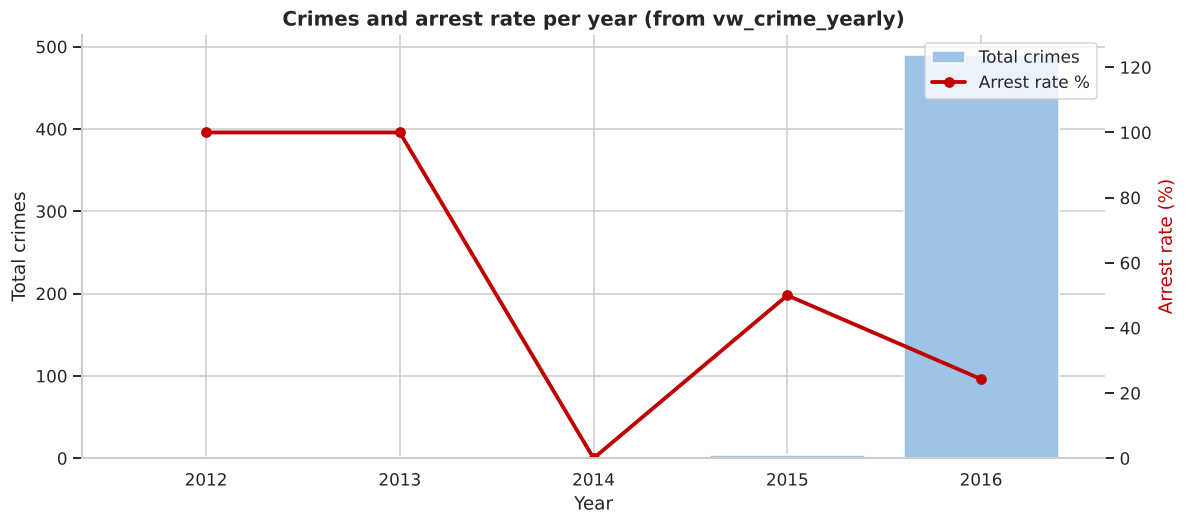

In [12]:
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(yearly["year"], yearly["total_crimes"], color="#9dc3e6", label="Total crimes")
ax1.set(xlabel="Year", ylabel="Total crimes", title="Crimes and arrest rate per year (from vw_crime_yearly)")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax1.set_xticks(yearly["year"])
ax2 = ax1.twinx()                                   # second y-axis for the rate
ax2.plot(yearly["year"], yearly["arrest_rate_pct"], color="#c00000", marker="o", linewidth=2.5,
         label="Arrest rate %")
ax2.set_ylabel("Arrest rate (%)", color="#c00000")
ax2.set_ylim(0, yearly["arrest_rate_pct"].max() * 1.3)
ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
cu.save_fig(fig, "uc4_01_yearly_from_mysql")
plt.show()

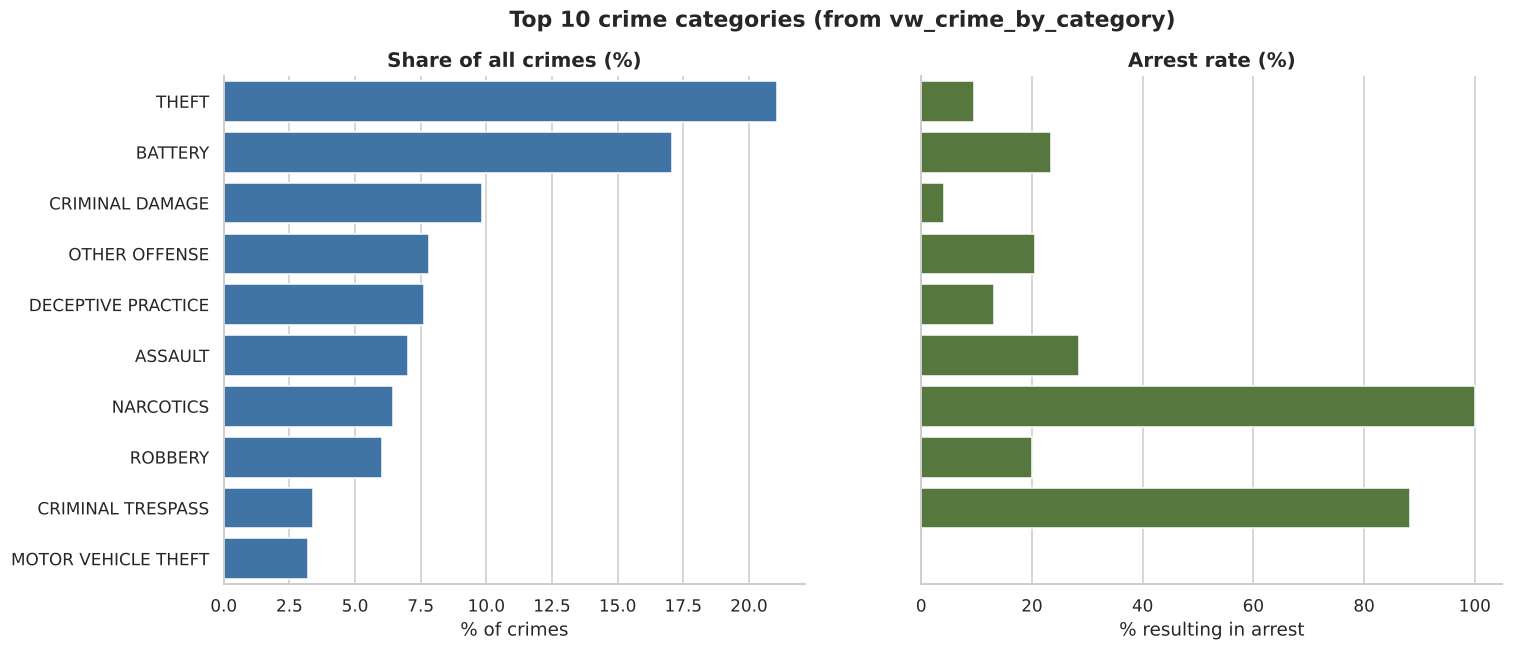

In [13]:
top = by_cat.head(10)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
sns.barplot(data=top, x="pct_of_total", y="primary_type", ax=axes[0], color="#2e75b6")
axes[0].set(title="Share of all crimes (%)", xlabel="% of crimes", ylabel="")
sns.barplot(data=top, x="arrest_rate_pct", y="primary_type", ax=axes[1], color="#548235")
axes[1].set(title="Arrest rate (%)", xlabel="% resulting in arrest", ylabel="")
fig.suptitle("Top 10 crime categories (from vw_crime_by_category)", fontweight="bold")
cu.save_fig(fig, "uc4_02_categories_from_mysql")
plt.show()

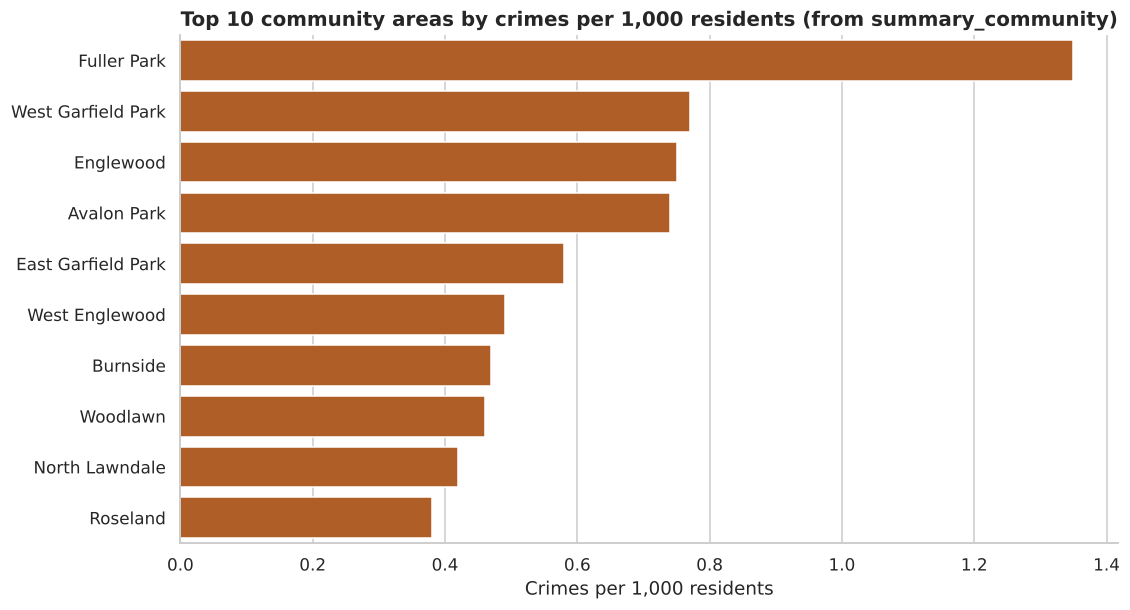

In [14]:
top_pc = community.nlargest(10, "crimes_per_1000_pop")
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=top_pc, x="crimes_per_1000_pop", y=top_pc["community_name"].str.title(),
            ax=ax, color="#c55a11")
ax.set(title="Top 10 community areas by crimes per 1,000 residents (from summary_community)",
       xlabel="Crimes per 1,000 residents", ylabel="")
cu.save_fig(fig, "uc4_03_community_per_capita_from_mysql")
plt.show()

## Close connections
Always close cursors/connections — open connections hold server resources.

In [15]:
cur.close()
cnx.close()
engine.dispose()
print("Connections closed")

Connections closed
